Ringforts as signals analysis 

In [1]:
# imports 
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import seaborn as sns

import numpy as np
from pysal.explore import esda
from pysal.lib import weights

from scipy.spatial import Voronoi, voronoi_plot_2d

/home/dylanf/Documents/GitHub/Artefact/Colab/2025_Version_2/.venv/lib/python3.12/site-packages/spaghetti/network.py:41: FutureWarning: The next major release of pysal/spaghetti (2.0.0) will drop support for all ``libpysal.cg`` geometries. This change is a first step in refactoring ``spaghetti`` that is expected to result in dramatically reduced runtimes for network instantiation and operations. Users currently requiring network and point pattern input as ``libpysal.cg`` geometries should prepare for this simply by converting to ``shapely`` geometries.
  warnings.warn(dep_msg, FutureWarning, stacklevel=1)
/home/dylanf/Documents/GitHub/Artefact/Colab/2025_Version_2/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


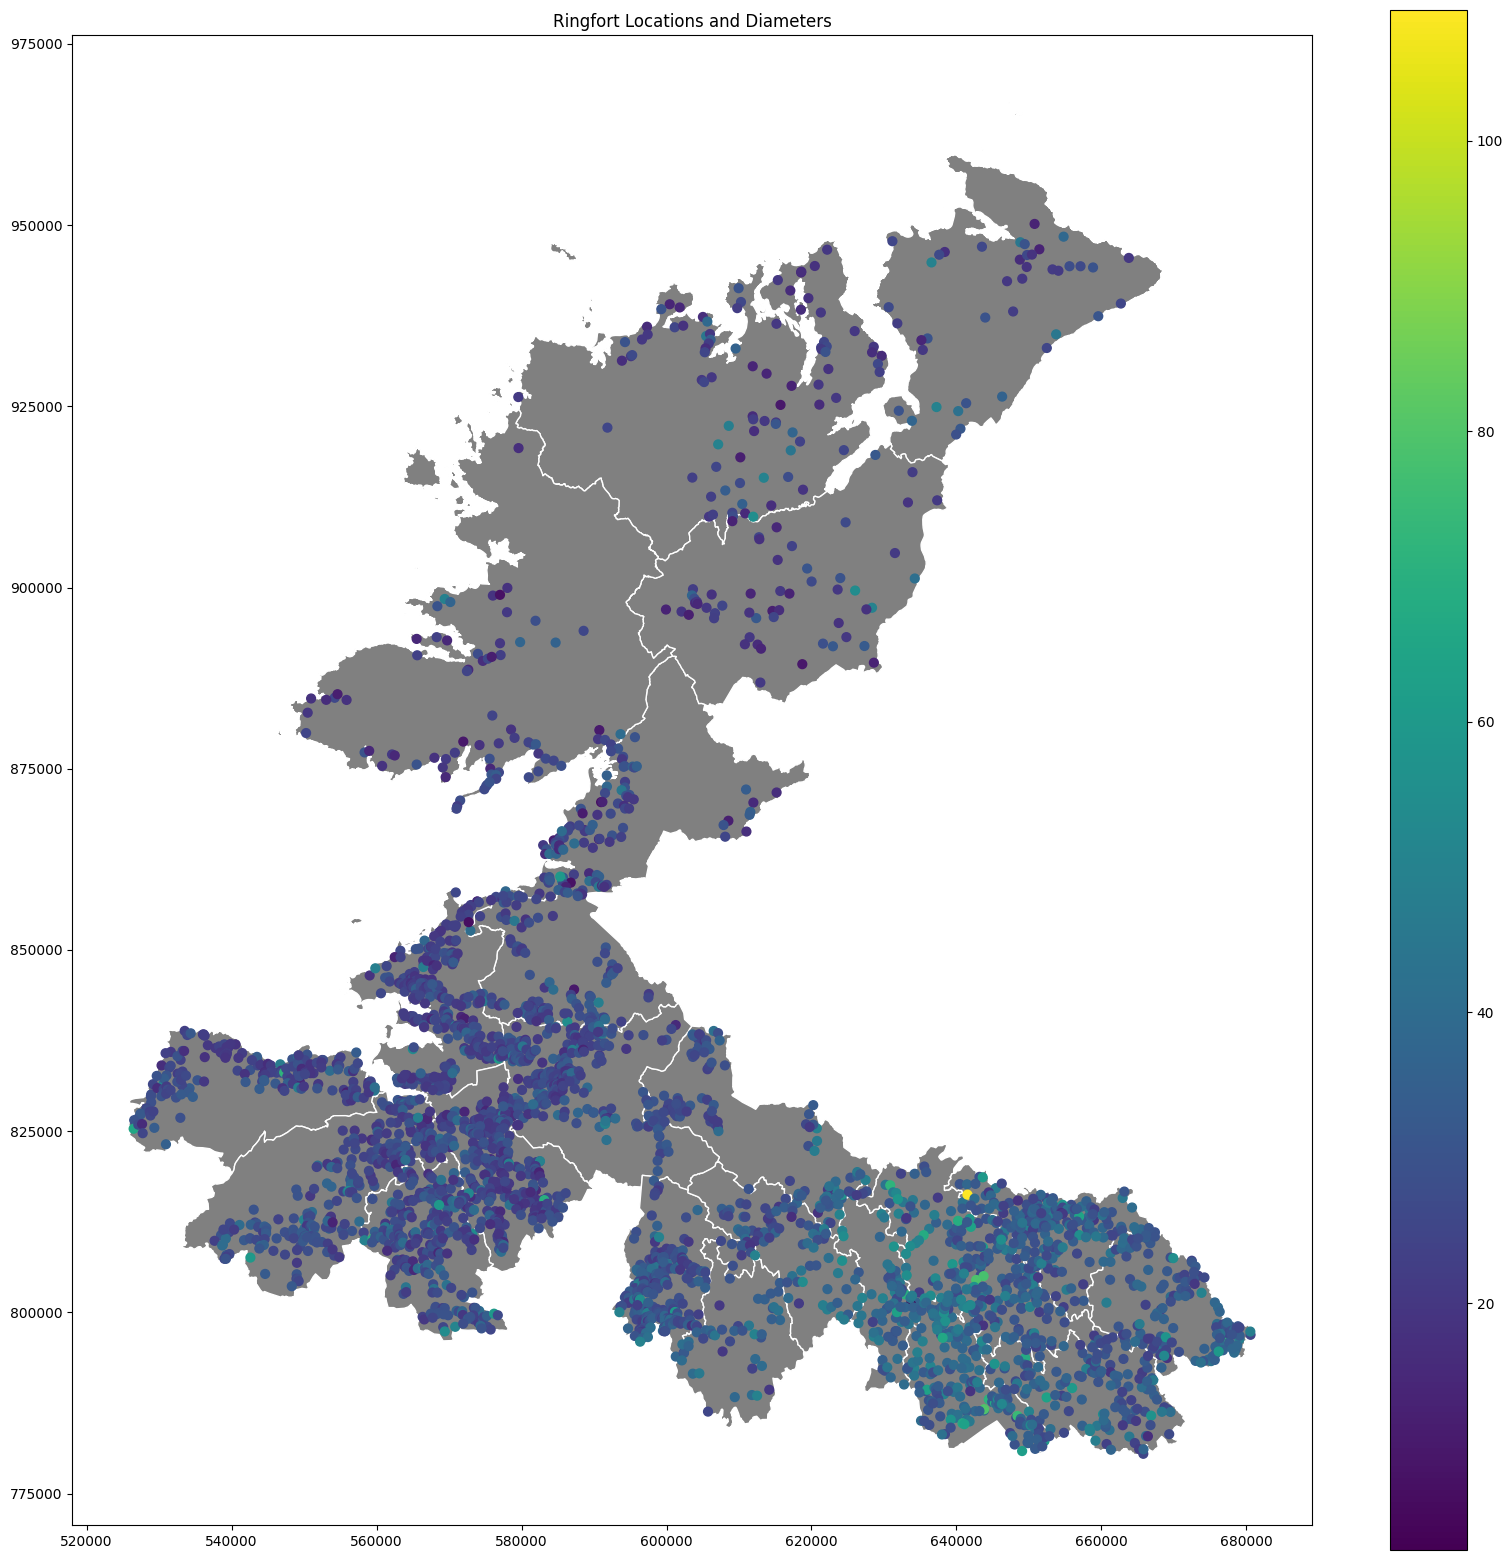

In [2]:
# Load map 
tuatha_nw_1600_mod = gpd.read_file('/home/dylanf/Documents/GitHub/data/Files1600/tuatha_nw_1600_mod.shp')


# Load the shapefile into a GeoDataFrame
ringforts = gpd.read_file('/home/dylanf/Documents/GitHub/data/Files1600/ringforts_with_diameter.shp')

# Basic plotting
fig, ax = plt.subplots(figsize=(20, 20))
tuatha_nw_1600_mod.plot(ax=ax, color='grey', edgecolor='white')
ringforts.plot(ax=ax, 
               column='diameter',  # Color by diameter
               legend=True,
               cmap='viridis',
               markersize=40)
plt.title('Ringfort Locations and Diameters')
plt.show()

In [3]:
# Ensure all data is in the same CRS
print("CRS Check:")
print(f"Ringforts CRS: {ringforts.crs}")
print(f"Tuatha CRS: {tuatha_nw_1600_mod.crs}")


CRS Check:
Ringforts CRS: EPSG:2157
Tuatha CRS: EPSG:2157


/home/dylanf/Documents/GitHub/Artefact/Colab/2025_Version_2/.venv/lib/python3.12/site-packages/libpysal/weights/distance.py:153: UserWarning: The weights matrix is not fully connected: 
 There are 32 disconnected components.
  W.__init__(self, neighbors, id_order=ids, **kwargs)


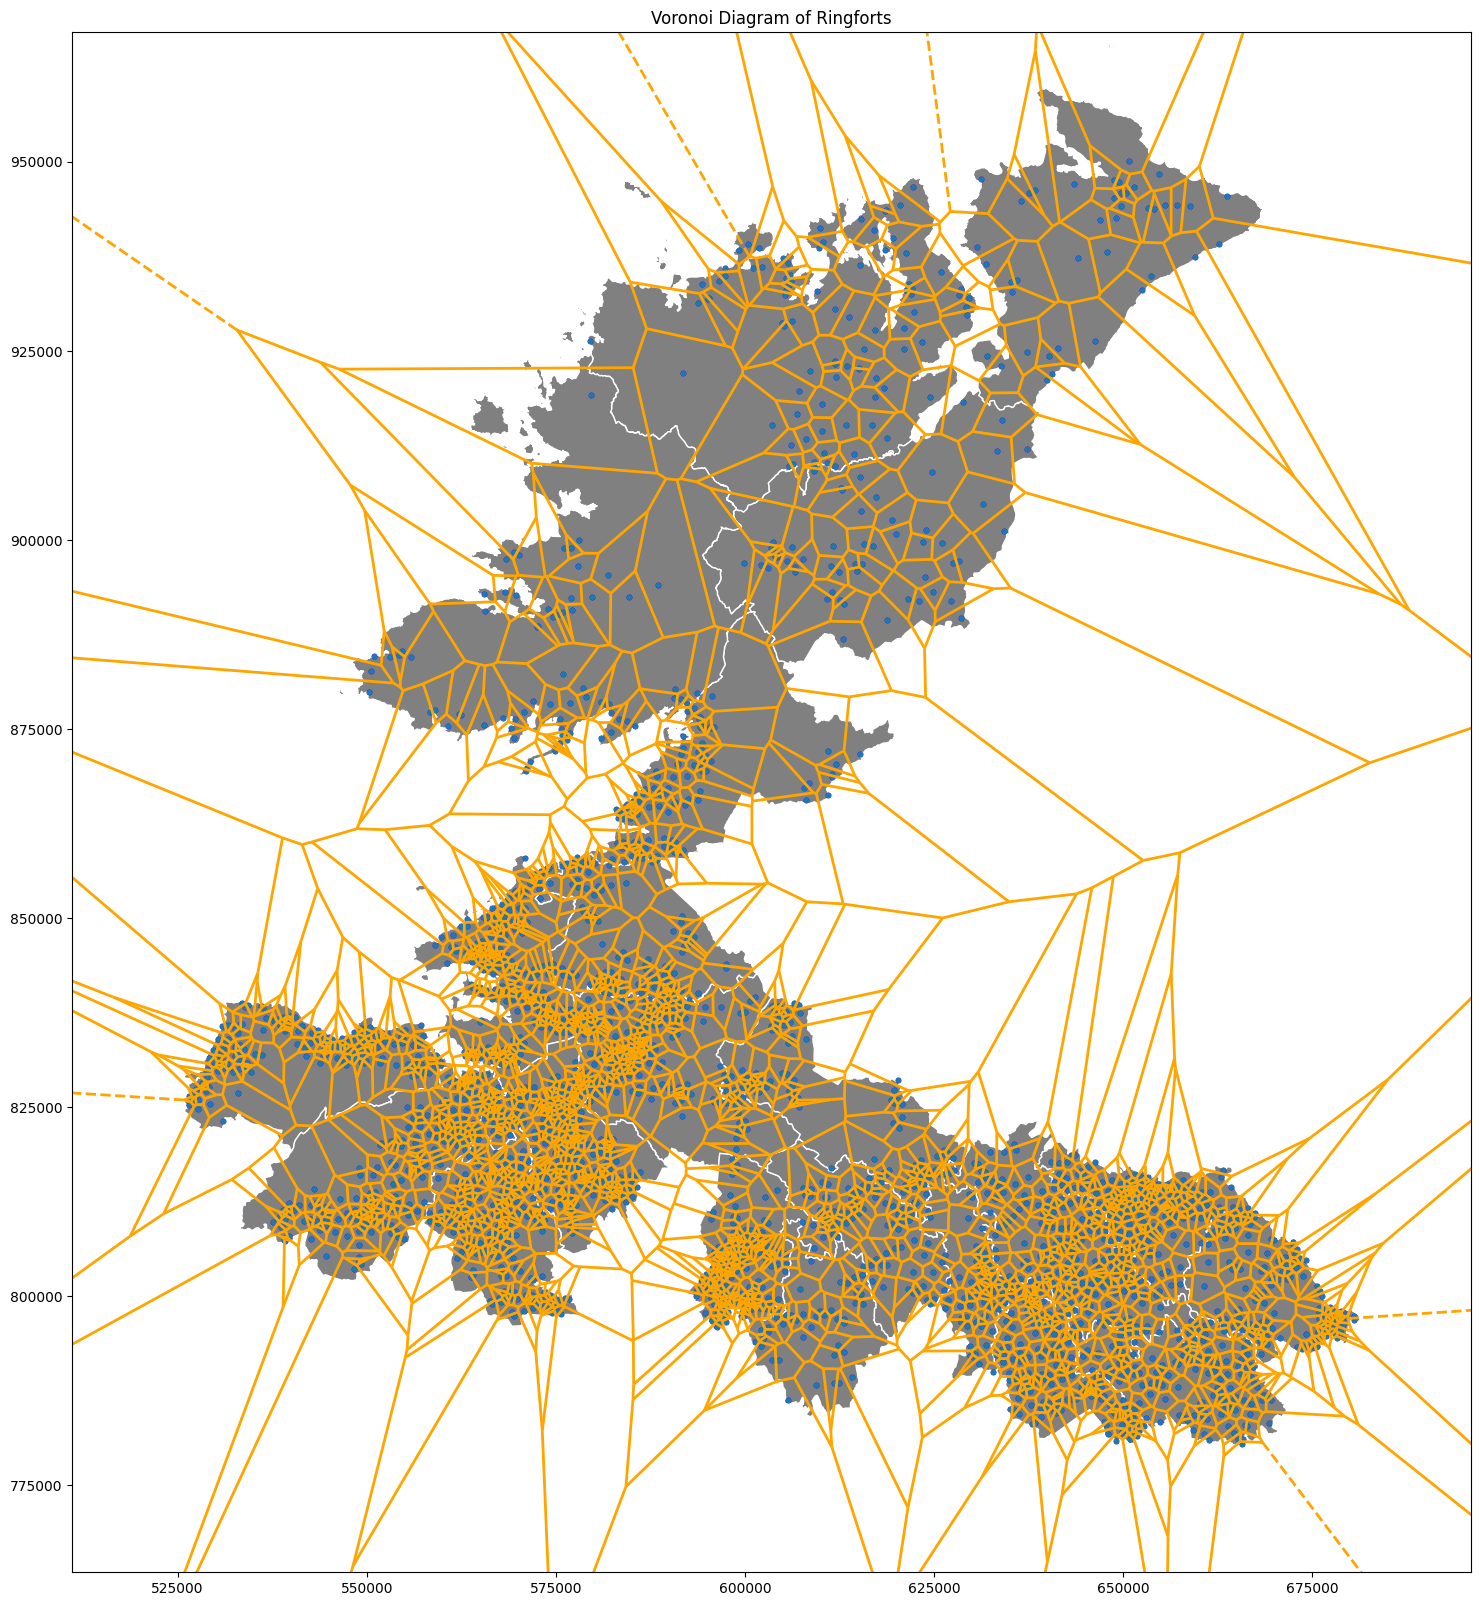

In [3]:
# Create spatial weights matrix for ringforts
knn = weights.KNN.from_dataframe(ringforts, k=3)

# Calculate Global Moran's I for diameter
moran_diameter = esda.Moran(ringforts['diameter'], knn)

# Calculate Local Moran's I
lisa = esda.Moran_Local(ringforts['diameter'], knn)

# Create visualization of clusters
"""fig, ax = plt.subplots(figsize=(15, 15))
tuatha_nw_1600_mod.plot(ax=ax, color='lightgrey', edgecolor='white')
ringforts.assign(lisa_cluster=lisa.q).plot(
    column='lisa_cluster',
    categorical=True,
    k=4,
    cmap='RdBu',
    markersize=50,
    legend=True,
    ax=ax
)
plt.title('Local Spatial Autocorrelation of Ringfort Diameters')
plt.show()"""

# Create Voronoi diagram
def voronoi_plot(points, ax=None):
    """Create a Voronoi diagram from points."""
    vor = Voronoi(points)
    if ax is None:
        fig, ax = plt.subplots()
    voronoi_plot_2d(vor, ax=ax, show_vertices=False, line_colors='orange', line_width=2)
    return ax

# Extract coordinates of ringforts
ringfort_coords = np.array(list(zip(ringforts.geometry.x, ringforts.geometry.y)))
# Create Voronoi diagram
fig, ax = plt.subplots(figsize=(20, 20))
tuatha_nw_1600_mod.plot(ax=ax, color='grey', edgecolor='white')
voronoi_plot(ringfort_coords, ax=ax)
plt.scatter(ringfort_coords[:, 0], ringfort_coords[:, 1], color='blue', s=10)
plt.title('Voronoi Diagram of Ringforts')
plt.show()

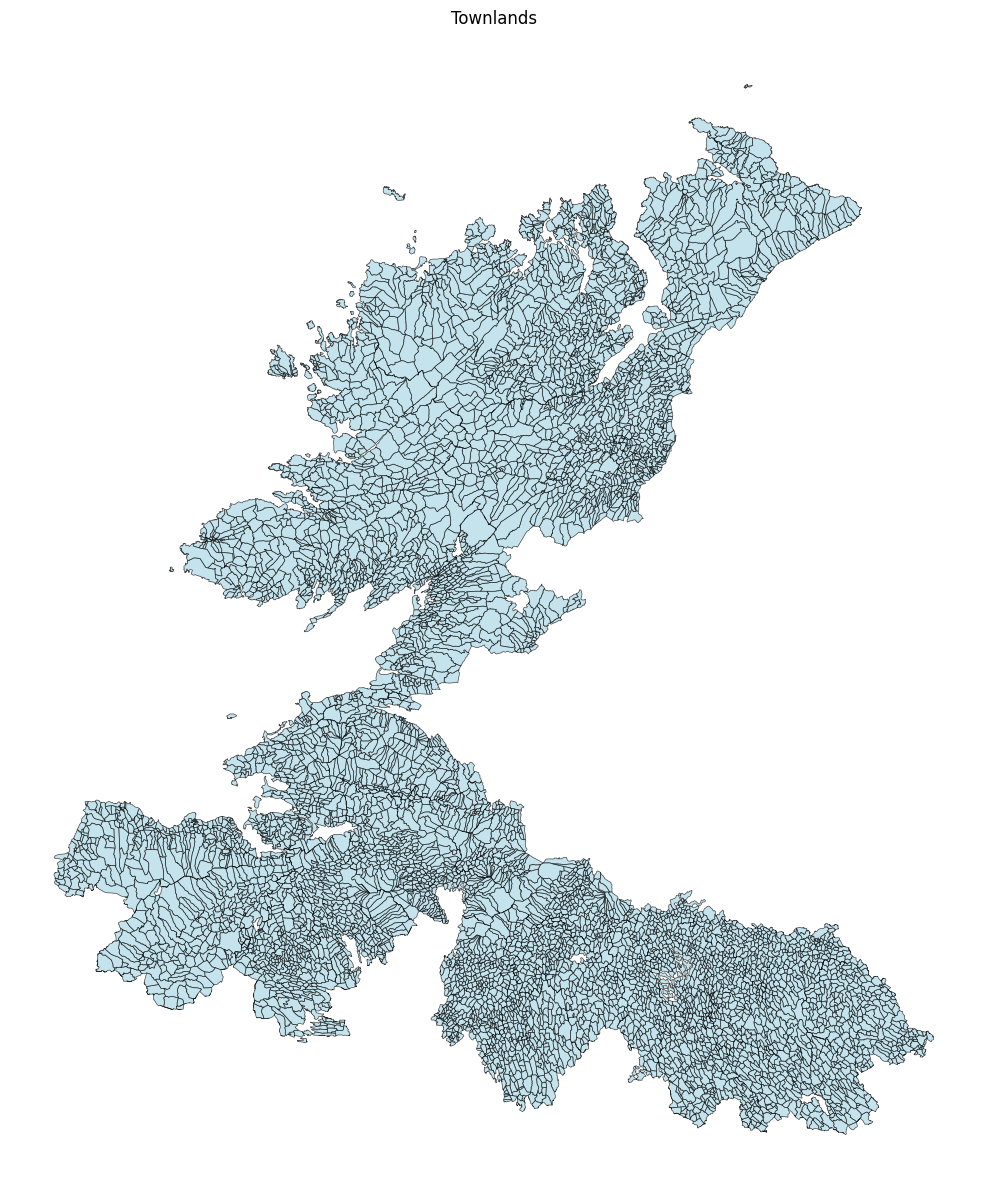

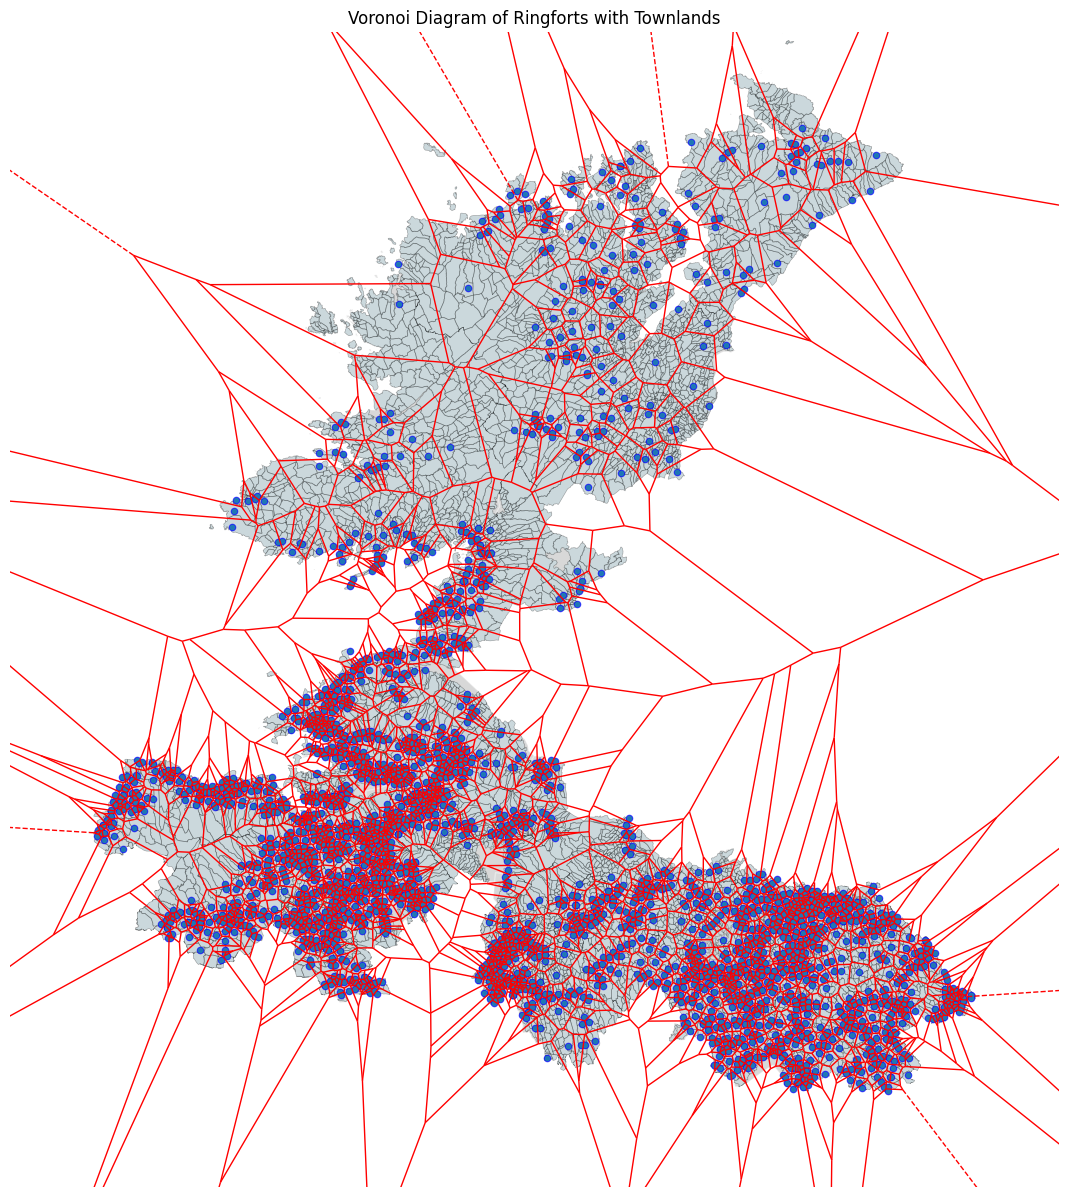

In [4]:
# 1. First, display just the townlands
townlands = gpd.read_file("/home/dylanf/Documents/GitHub/data/Files1600/townlands_nw.shp")

fig, ax = plt.subplots(figsize=(15, 15))
townlands.plot(ax=ax, 
              color='lightblue',  # Use a lighter color to see boundaries
              edgecolor='black',  # Add edge color to see polygon boundaries
              linewidth=0.5,      # Thin lines for boundaries
              alpha=0.7)          # Some transparency
plt.title('Townlands')
plt.axis('off')  # Remove axes for cleaner map
plt.show()

# 2. Now combine townlands with Voronoi diagram
fig, ax = plt.subplots(figsize=(15, 15))

# Plot base territory boundaries
tuatha_nw_1600_mod.plot(ax=ax, color='grey', edgecolor='white', alpha=0.3)

# Plot townlands with transparency
townlands.plot(ax=ax, 
              color='lightblue', 
              edgecolor='black',
              linewidth=0.5,
              alpha=0.3)

# Create Voronoi diagram
vor = Voronoi(ringfort_coords)
voronoi_plot_2d(vor, ax=ax, 
                show_vertices=False, 
                line_colors='red',
                line_width=1)

# Add ringfort points
plt.scatter(ringfort_coords[:, 0], 
           ringfort_coords[:, 1], 
           color='blue',
           s=20,
           alpha=0.7)

plt.title('Voronoi Diagram of Ringforts with Townlands')
plt.axis('off')
plt.show()

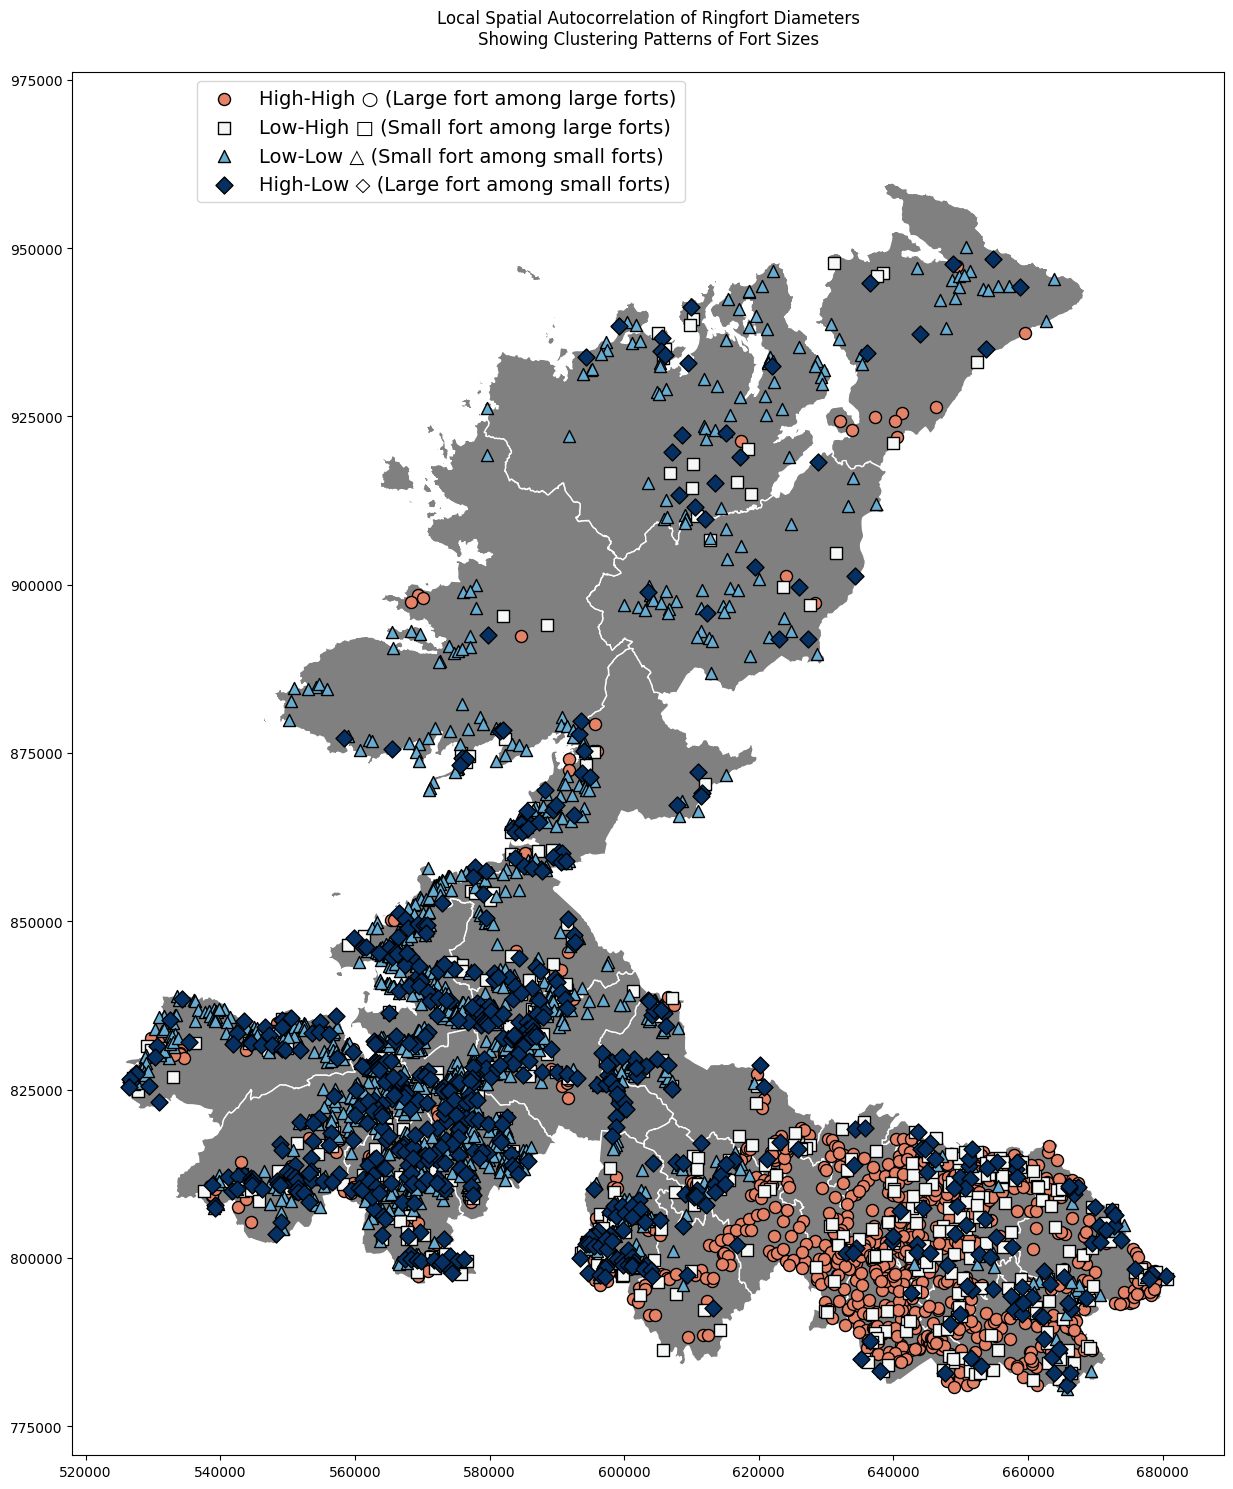

In [6]:
# Create visualization of clusters with better labels and shapes
fig, ax = plt.subplots(figsize=(15, 15))
tuatha_nw_1600_mod.plot(ax=ax, color='grey', edgecolor='white')

# Define markers for each category
markers = {
    1: 'o',  # circle for High-High
    2: 's',  # square for Low-High
    3: '^',  # triangle for Low-Low
    4: 'D'   # diamond for High-Low
}

lisa_labels = {
    1: 'High-High ○ (Large fort among large forts)',
    2: 'Low-High □ (Small fort among large forts)',
    3: 'Low-Low △ (Small fort among small forts)',
    4: 'High-Low ◇ (Large fort among small forts)'
}

# Plot each category separately with different markers
for category in range(1, 5):
    mask = lisa.q == category
    ringforts[mask].plot(
        ax=ax,
        marker=markers[category],
        markersize=75,
        color=plt.cm.RdBu(0.25 * category),  # Using RdBu colormap
        label=lisa_labels[category],
        edgecolor='black',
        linewidth=1
    )

plt.title('Local Spatial Autocorrelation of Ringfort Diameters\n' + 
          'Showing Clustering Patterns of Fort Sizes', pad=20)

# Modified legend position to be closer to the map
plt.legend(bbox_to_anchor=(0.10, 1), loc='upper left', fontsize=14)
plt.tight_layout()
plt.show()

/tmp/ipykernel_85382/2311582154.py:137: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  territory_boundaries = territories.geometry.boundary.unary_union


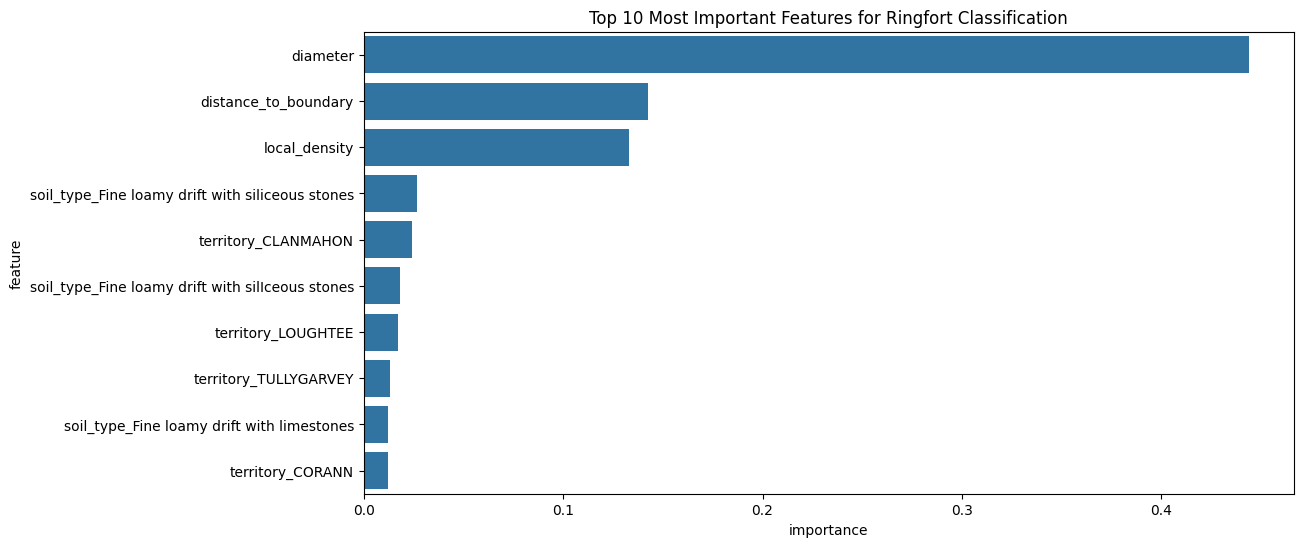

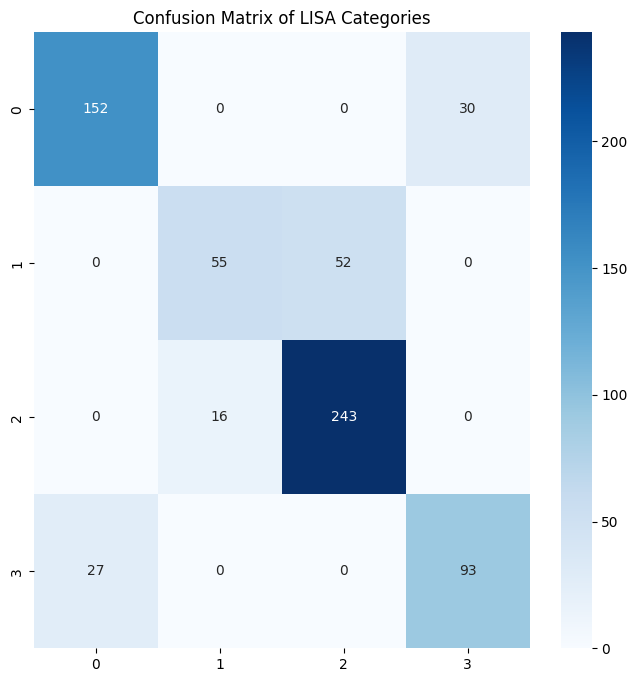

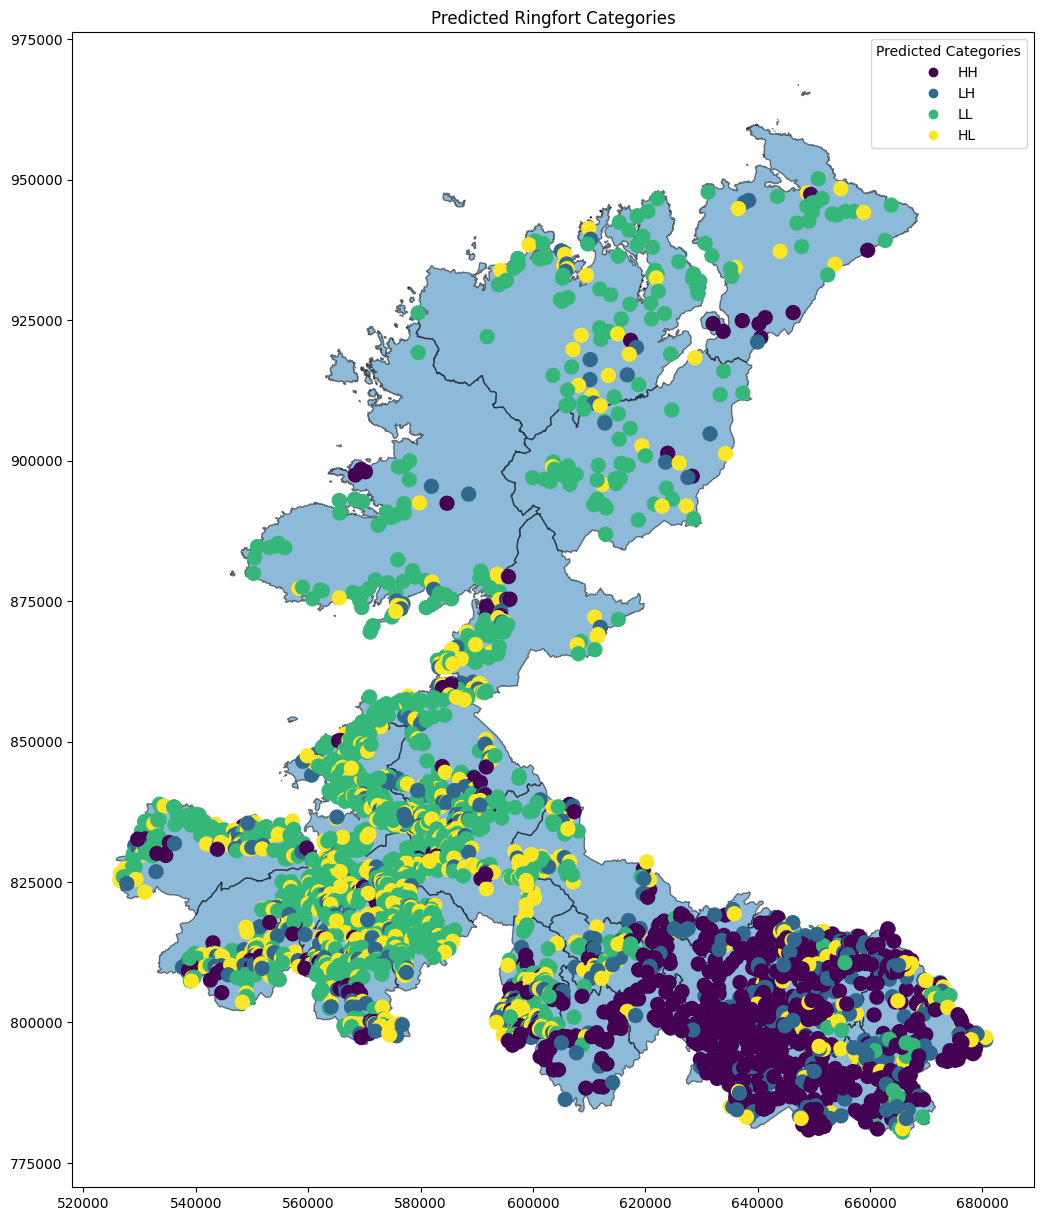


Detailed Territory Analysis:
--------------------------------------------------

BOYLAGH:
HH: 4 ringforts (5.33%)
LH: 6 ringforts (8.00%)
LL: 56 ringforts (74.67%)
HL: 9 ringforts (12.00%)

CARBURY:
HH: 2 ringforts (0.74%)
LH: 16 ringforts (5.93%)
LL: 205 ringforts (75.93%)
HL: 47 ringforts (17.41%)

CARRIGALLEN:
HH: 37 ringforts (49.33%)
LH: 12 ringforts (16.00%)
LL: 16 ringforts (21.33%)
HL: 10 ringforts (13.33%)

CASTLERAHAN:
HH: 70 ringforts (55.56%)
LH: 29 ringforts (23.02%)
LL: 10 ringforts (7.94%)
HL: 17 ringforts (13.49%)

CLANKEE:
HH: 81 ringforts (57.04%)
LH: 31 ringforts (21.83%)
LL: 15 ringforts (10.56%)
HL: 15 ringforts (10.56%)

CLANMAHON:
HH: 143 ringforts (81.25%)
LH: 27 ringforts (15.34%)
LL: 1 ringforts (0.57%)
HL: 5 ringforts (2.84%)

CORANN:
HH: 19 ringforts (8.02%)
LH: 42 ringforts (17.72%)
LL: 106 ringforts (44.73%)
HL: 70 ringforts (29.54%)

DRUMAHAIRE:
HH: 10 ringforts (3.89%)
LH: 27 ringforts (10.51%)
LL: 147 ringforts (57.20%)
HL: 73 ringforts (28.40%)

INISH

In [13]:
from spatial_analysis import calculate_boundary_distance, calculate_local_density



# 1. First, let's prepare our feature set
def prepare_ringfort_features(ringforts, territories):
    # Spatial join to get territory information for each ringfort
    ringforts_with_territory = gpd.sjoin(ringforts, territories, how='left', predicate='within')
    
    # Create feature matrix
    features_df = pd.DataFrame()
    
    # Basic features
    features_df['diameter'] = ringforts_with_territory['diameter']
    features_df['lisa_category'] = ringforts_with_territory['lisa_category']  # From previous LISA analysis
    features_df['soil_type'] = ringforts_with_territory['substrate']
    
    # Add territory/federation information
    features_df['territory'] = ringforts_with_territory['ENGLISH']
    features_df['chief_king_territory'] = ringforts_with_territory['chief_king']
    
    # Calculate spatial features
    features_df['distance_to_boundary'] = calculate_boundary_distance(ringforts, territories)
    features_df['local_density'] = calculate_local_density(ringforts)
    
    # Convert categorical variables to dummy variables
    features_encoded = pd.get_dummies(features_df, columns=['soil_type', 'territory'])
    
    return features_encoded

# 2. Train a Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

def analyze_ringfort_patterns(features_df):
    # Prepare data
    X = features_df.drop(['lisa_category'], axis=1)
    y = features_df['lisa_category']
    
    # Split data
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    # Train model
    rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
    rf_model.fit(X_train, y_train)
    
    # Get predictions
    y_pred = rf_model.predict(X_test)
    
    # Analyze feature importance
    feature_importance = pd.DataFrame({
        'feature': X.columns,
        'importance': rf_model.feature_importances_
    }).sort_values('importance', ascending=False)
    
    return rf_model, feature_importance, y_test, y_pred

def visualize_results(model, feature_importance, y_test, y_pred, territories, X, ringforts):
    """
    Visualize the results of the ringfort analysis.
    
    Args:
        model: Trained RandomForest model
        feature_importance: DataFrame containing feature importance scores
        y_test: Test set labels
        y_pred: Predicted labels
        territories: GeoDataFrame containing territory boundaries
        X: Features DataFrame used for prediction
        ringforts: GeoDataFrame containing ringfort locations
        
    Returns:
        GeoDataFrame: Ringforts with predictions added as a new column
    """
    # Plot feature importance
    plt.figure(figsize=(12, 6))
    sns.barplot(x='importance', y='feature', data=feature_importance.head(10))
    plt.title('Top 10 Most Important Features for Ringfort Classification')
    plt.show()
    
    # Plot confusion matrix
    plt.figure(figsize=(8, 8))
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title('Confusion Matrix of LISA Categories')
    plt.show()
    
    # Map predictions
    fig, ax = plt.subplots(figsize=(15, 15))
    territories.plot(ax=ax, alpha=0.5, edgecolor='black')
    
    # Exclude the target variable from features for prediction
    features_for_prediction = X.drop(columns=['lisa_category'], errors='ignore')
    
    # Get predictions for all ringforts
    predictions = model.predict(features_for_prediction)
    
    # Create a copy of ringforts with predictions
    ringforts_with_predictions = ringforts.copy()
    ringforts_with_predictions['predicted_category'] = predictions
    
    # Plot ringforts colored by predicted category
    scatter = ax.scatter(ringforts.geometry.x, ringforts.geometry.y,
                        c=predictions,
                        cmap='viridis',
                        s=100)
    plt.legend(scatter.legend_elements()[0], 
              ['HH', 'LH', 'LL', 'HL'],
              title='Predicted Categories')
    plt.title('Predicted Ringfort Categories')
    plt.show()
    
    return ringforts_with_predictions


import geopandas as gpd
import numpy as np
from scipy.spatial import cKDTree
from shapely.geometry import Point
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

def calculate_boundary_distance(ringforts, territories):
    """
    Calculate the minimum distance from each ringfort to the nearest territory boundary.
    
    Args:
        ringforts (GeoDataFrame): GeoDataFrame containing ringfort locations
        territories (GeoDataFrame): GeoDataFrame containing territory boundaries
        
    Returns:
        Series: Minimum distances from each ringfort to the nearest territory boundary
    """
    # Get the boundary of all territories
    territory_boundaries = territories.geometry.boundary.unary_union
    
    # Calculate distance from each ringfort to the boundary
    distances = ringforts.geometry.apply(
        lambda x: territory_boundaries.distance(x)
    )
    
    return distances

def calculate_local_density(ringforts, radius=5000):
    """
    Calculate the local density of ringforts within a specified radius.
    
    Args:
        ringforts (GeoDataFrame): GeoDataFrame containing ringfort locations
        radius (float): Search radius in meters (default: 5000m)
        
    Returns:
        Series: Local density values for each ringfort
    """
    # Get coordinates of ringforts
    coords = np.array([(geom.x, geom.y) for geom in ringforts.geometry])
    
    # Create KDTree for efficient nearest neighbor search
    tree = cKDTree(coords)
    
    # Find all points within radius for each point
    counts = tree.query_ball_point(coords, radius, return_length=True)
    
    # Convert to density (points per square kilometer)
    area = np.pi * (radius/1000)**2  # Area in square kilometers
    densities = counts / area
    
    return densities

def visualize_results(model, feature_importance, y_test, y_pred, territories, X, ringforts):
    """
    Visualize the results of the ringfort analysis.
    
    Args:
        model: Trained RandomForest model
        feature_importance: DataFrame containing feature importance scores
        y_test: Test set labels
        y_pred: Predicted labels
        territories: GeoDataFrame containing territory boundaries
        X: Features DataFrame used for prediction
        ringforts: GeoDataFrame containing ringfort locations
        
    Returns:
        GeoDataFrame: Ringforts with predictions added as a new column
    """
    # Plot feature importance
    plt.figure(figsize=(12, 6))
    sns.barplot(x='importance', y='feature', data=feature_importance.head(10))
    plt.title('Top 10 Most Important Features for Ringfort Classification')
    plt.show()
    
    # Plot confusion matrix
    plt.figure(figsize=(8, 8))
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title('Confusion Matrix of LISA Categories')
    plt.show()
    
    # Map predictions
    fig, ax = plt.subplots(figsize=(15, 15))
    territories.plot(ax=ax, alpha=0.5, edgecolor='black')
    
    # Exclude the target variable from features for prediction
    features_for_prediction = X.drop(columns=['lisa_category'], errors='ignore')
    
    # Get predictions for all ringforts
    predictions = model.predict(features_for_prediction)
    
    # Create a copy of ringforts with predictions
    ringforts_with_predictions = ringforts.copy()
    ringforts_with_predictions['predicted_category'] = predictions
    
    # Plot ringforts colored by predicted category
    scatter = ax.scatter(ringforts.geometry.x, ringforts.geometry.y,
                        c=predictions,
                        cmap='viridis',
                        s=100)
    plt.legend(scatter.legend_elements()[0], 
              ['HH', 'LH', 'LL', 'HL'],
              title='Predicted Categories')
    plt.title('Predicted Ringfort Categories')
    plt.show()
    
    return ringforts_with_predictions

'''def analyze_territorial_patterns(ringforts_with_predictions, territories):
    """
    Analyze the distribution of ringfort categories by territory.
    
    Args:
        ringforts_with_predictions: GeoDataFrame containing ringforts with predicted categories
        territories: GeoDataFrame containing territory boundaries
        
    Returns:
        DataFrame: Territory patterns analysis
    """
    # Perform spatial join to get territory information for each ringfort
    ringforts_with_territories = gpd.sjoin(ringforts_with_predictions, territories, how='left', predicate='within')
    
    # Calculate proportion of each predicted category per territory
    territory_patterns = ringforts_with_territories.groupby('ENGLISH')['predicted_category'].value_counts(normalize=True).unstack()
    
    # Plot territorial differences
    plt.figure(figsize=(15, 8))
    territory_patterns.plot(kind='bar', stacked=True)
    plt.title('Distribution of Predicted Ringfort Categories by Territory')
    plt.xlabel('Territory')
    plt.ylabel('Proportion')
    plt.legend(title='Category')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
    
    # Calculate summary statistics
    print("\nTerritory Analysis Summary:")
    print("-" * 50)
    print(f"Total territories analyzed: {len(territory_patterns)}")
    print(f"Total ringforts analyzed: {len(ringforts_with_territories)}")
    print("\nAverage distribution of categories across territories:")
    print(territory_patterns.mean())
    
    return territory_patterns'''


def analyze_territorial_patterns(ringforts_with_predictions, territories):
    """
    Analyze the distribution of ringfort categories by territory.
    
    Args:
        ringforts_with_predictions: GeoDataFrame containing ringforts with predicted categories
        territories: GeoDataFrame containing territory boundaries
        
    Returns:
        DataFrame: Territory patterns analysis
    """
    # Perform spatial join to get territory information for each ringfort
    ringforts_with_territories = gpd.sjoin(ringforts_with_predictions, territories, how='left', predicate='within')
    
    # Calculate proportion of each predicted category per territory
    territory_patterns = ringforts_with_territories.groupby('ENGLISH')['predicted_category'].value_counts(normalize=True).unstack()
    
    # Print detailed numerical results
    print("\nDetailed Territory Analysis:")
    print("-" * 50)
    
    # Print counts and proportions for each territory
    for territory in territory_patterns.index:
        print(f"\n{territory}:")
        counts = ringforts_with_territories[ringforts_with_territories['ENGLISH'] == territory]['predicted_category'].value_counts()
        proportions = territory_patterns.loc[territory]
        for category in [1, 2, 3, 4]:
            category_name = {1: 'HH', 2: 'LH', 3: 'LL', 4: 'HL'}[category]
            count = counts.get(category, 0)
            prop = proportions.get(category, 0)
            print(f"{category_name}: {count} ringforts ({prop:.2%})")
    
    # Calculate and print summary statistics
    print("\nSummary Statistics:")
    print("-" * 50)
    print(f"Total territories analyzed: {len(territory_patterns)}")
    print(f"Total ringforts analyzed: {len(ringforts_with_territories)}")
    print("\nAverage distribution of categories across territories:")
    print(territory_patterns.mean())
    
    # Print feature importance from the model
    print("\nTop 10 Most Important Features:")
    print(importance.head(10))
    
    return territory_patterns


# Run the analysis
features_df = prepare_ringfort_features(ringforts, tuatha_nw_1600_mod)
model, importance, y_test, y_pred = analyze_ringfort_patterns(features_df)
ringforts_with_predictions = visualize_results(model, importance, y_test, y_pred, tuatha_nw_1600_mod, features_df, ringforts)
territory_patterns = analyze_territorial_patterns(ringforts_with_predictions, tuatha_nw_1600_mod)

In [14]:
# Calculate correlation between diameter and distance to boundary
correlation = features_df['diameter'].corr(features_df['distance_to_boundary'])
print(f"Correlation between diameter and distance to boundary: {correlation:.3f}")

Correlation between diameter and distance to boundary: -0.101


In [15]:
# Calculate average diameter by distance ranges
distance_bins = pd.cut(features_df['distance_to_boundary'], bins=5)
diameter_by_distance = features_df.groupby(distance_bins)['diameter'].mean()
print("\nAverage diameter by distance to boundary:")
print(diameter_by_distance)


Average diameter by distance to boundary:
distance_to_boundary
(-7.166, 2226.714]       30.302108
(2226.714, 4449.479]     29.166683
(4449.479, 6672.245]     28.350549
(6672.245, 8895.011]     24.576087
(8895.011, 11117.776]    24.850000
Name: diameter, dtype: float64


/tmp/ipykernel_85382/1439807926.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  diameter_by_distance = features_df.groupby(distance_bins)['diameter'].mean()


In [17]:
features_df.columns

Index(['diameter', 'lisa_category', 'chief_king_territory',
       'distance_to_boundary', 'local_density', 'soil_type_Blown sand/Dune',
       'soil_type_Clayey drift with limestones',
       'soil_type_Clayey drift with siliceous stones',
       'soil_type_Coarse loamy drift with igneous and metamorphic stones',
       'soil_type_Coarse loamy drift with limestones',
       'soil_type_Coarse loamy drift with siliceous stones',
       'soil_type_Fine loamy drift with limestones',
       'soil_type_Fine loamy drift with silIceous stones',
       'soil_type_Fine loamy drift with siliceous stones',
       'soil_type_Fine loamy over limestone bedrock',
       'soil_type_Fine loamy over sandstone bedrock',
       'soil_type_Fine loamy over shale and slate bedrock',
       'soil_type_Fine loamy over shale bedrock',
       'soil_type_Fine loamy over shale or slate bedrock',
       'soil_type_Lake alluvium',
       'soil_type_Loamy over gneiss and schist bedrock',
       'soil_type_Loamy over 

In [23]:
# Calculate correlation by territory
territory_correlations = features_df.groupby('territory_DRUMAHAIRE').apply(
    lambda x: x['diameter'].corr(x['distance_to_boundary'])
)
print("\nCorrelation by territory:")
print(territory_correlations)


Correlation by territory:
territory_DRUMAHAIRE
False   -0.093381
True    -0.071038
dtype: float64


/tmp/ipykernel_85382/276960831.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  territory_correlations = features_df.groupby('territory_DRUMAHAIRE').apply(


In [19]:
from scipy.stats import f_oneway
# Test for significant differences between distance groups
f_stat, p_value = f_oneway(
    features_df[features_df['distance_to_boundary'] <= 2226.714]['diameter'],
    features_df[features_df['distance_to_boundary'] > 8895.011]['diameter']
)
print(f"\nANOVA p-value: {p_value:.4f}")


ANOVA p-value: 0.0737


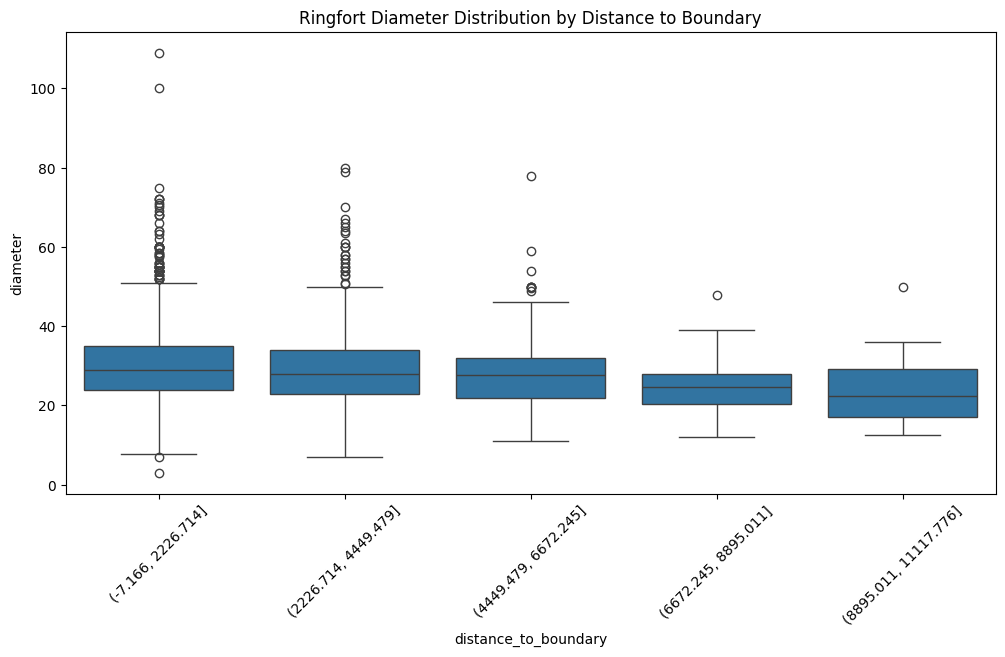

In [20]:
# Create box plot of diameter by distance range
plt.figure(figsize=(12, 6))
sns.boxplot(x=distance_bins, y=features_df['diameter'])
plt.xticks(rotation=45)
plt.title('Ringfort Diameter Distribution by Distance to Boundary')
plt.show()

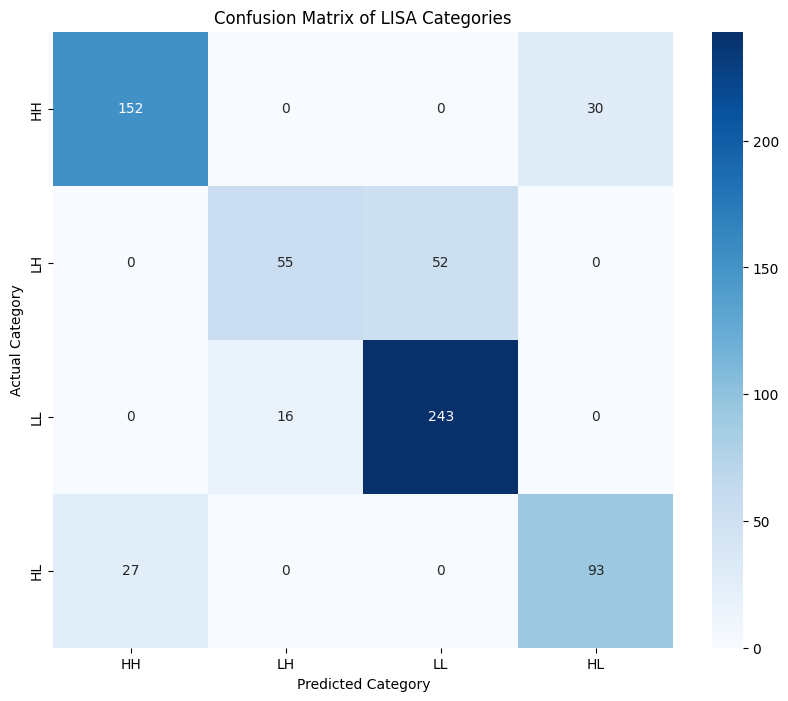

In [12]:
# Display the confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(confusion_matrix(y_test, y_pred), 
            annot=True, 
            fmt='d', 
            cmap='Blues',
            xticklabels=['HH', 'LH', 'LL', 'HL'],
            yticklabels=['HH', 'LH', 'LL', 'HL'])
plt.title('Confusion Matrix of LISA Categories')
plt.xlabel('Predicted Category')
plt.ylabel('Actual Category')
plt.show()

In [13]:
# Get the confusion matrix values
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix Values:")
print(cm)
print("\nCategory Labels: ['HH', 'LH', 'LL', 'HL']")

Confusion Matrix Values:
[[152   0   0  30]
 [  0  55  52   0]
 [  0  16 243   0]
 [ 27   0   0  93]]

Category Labels: ['HH', 'LH', 'LL', 'HL']


In [6]:
# Add LISA categories to your ringfort GeoDataFrame
ringforts['lisa_category'] = lisa.q
ringforts['lisa_category_name'] = ringforts['lisa_category'].map({
    1: 'High-High',
    2: 'Low-High',
    3: 'Low-Low',
    4: 'High-Low'
})

# Add significance levels if available
ringforts['lisa_pvalue'] = lisa.p_sim

In [7]:
tuatha_nw_1600_mod.columns


Index(['BY_ID', 'ENGLISH', 'GAEILGE', 'LOGAINM_ID', 'AIREACHT', 'FEDERATION',
       'PROVINCE', 'GUID', 'CENTROID_X', 'CENTROID_Y', 'AREA', 'OBJECTID',
       'Shape__Are', 'Shape__Len', 'connection', 'chief_king', 'connecti_1',
       'geometry'],
      dtype='object')

In [8]:
ringforts.columns


Index(['OID_', 'OBJECTID', 'ENTITY_ID', 'CLASS_CODE', 'SMRS', 'COUNTY',
       'TOWNLAND', 'COUNTY_ID', 'ZONE_ID', 'ITM_E', 'ITM_N', 'LATITUDE',
       'LONGITUDE', 'MONUMENT_T', 'FIRST_EDIT', 'LATEST_EDI', 'WEBSITE_LI',
       'WEB_NOTES', 'Boundary_I', 'Intersecti', 'signal_med', 'substrate',
       'diameter', 'geometry', 'lisa_category', 'lisa_category_name',
       'lisa_pvalue'],
      dtype='object')

In [20]:
print("Columns in ringforts_with_predictions:")
print(ringforts_with_predictions.columns)

print("\nColumns in tuatha_nw_1600_mod:")
print(tuatha_nw_1600_mod.columns)

Columns in ringforts_with_predictions:
Index(['OID_', 'OBJECTID', 'ENTITY_ID', 'CLASS_CODE', 'SMRS', 'COUNTY',
       'TOWNLAND', 'COUNTY_ID', 'ZONE_ID', 'ITM_E', 'ITM_N', 'LATITUDE',
       'LONGITUDE', 'MONUMENT_T', 'FIRST_EDIT', 'LATEST_EDI', 'WEBSITE_LI',
       'WEB_NOTES', 'Boundary_I', 'Intersecti', 'signal_med', 'substrate',
       'diameter', 'geometry', 'lisa_category', 'lisa_category_name',
       'lisa_pvalue', 'predicted_category'],
      dtype='object')

Columns in tuatha_nw_1600_mod:
Index(['BY_ID', 'ENGLISH', 'GAEILGE', 'LOGAINM_ID', 'AIREACHT', 'FEDERATION',
       'PROVINCE', 'GUID', 'CENTROID_X', 'CENTROID_Y', 'AREA', 'OBJECTID',
       'Shape__Are', 'Shape__Len', 'connection', 'chief_king', 'geometry'],
      dtype='object')


In [26]:
# Calculate category distribution by territory
territory_distribution = ringforts_with_predictions.groupby('COUNTY')['predicted_category'].value_counts(normalize=True).unstack()

# Calculate density of each category
def calculate_category_density(territory_name):
    territory = tuatha_nw_1600_mod[tuatha_nw_1600_mod['AIREACHT'] == territory_name]
    territory_area = territory.geometry.area.sum() / 1e6  # Convert to square kilometers
    counts = ringforts_with_predictions[ringforts_with_predictions['COUNTY'] == territory_name]['predicted_category'].value_counts()
    return counts / territory_area

# Calculate for each territory
territory_densities = {}
for territory in tuatha_nw_1600_mod['AIREACHT']:
    territory_densities[territory] = calculate_category_density(territory)

# Print the results
print("Category Distribution by Territory (Proportions):")
print(territory_distribution)
print("\nCategory Density by Territory (Ringforts per square kilometer):")
for territory, densities in territory_densities.items():
    print(f"\n{territory}:")
    print(densities)

Category Distribution by Territory (Proportions):
predicted_category         1         2         3         4
COUNTY                                                    
CAVAN               0.613346  0.211973  0.071639  0.103042
DONEGAL             0.072022  0.091413  0.645429  0.191136
LEITRIM             0.226519  0.149171  0.406077  0.218232
SLIGO               0.051053  0.108590  0.599676  0.240681

Category Density by Territory (Ringforts per square kilometer):

Dún na nGall:
Series([], Name: count, dtype: float64)

An Cabhán:
Series([], Name: count, dtype: float64)

Liatroim:
Series([], Name: count, dtype: float64)

Sligeach:
Series([], Name: count, dtype: float64)


In [28]:
# Calculate category distribution by territory using English names
territory_distribution = ringforts_with_predictions.groupby('COUNTY')['predicted_category'].value_counts(normalize=True).unstack()

# Calculate density of each category
def calculate_category_density(territory_name):
    territory = tuatha_nw_1600_mod[tuatha_nw_1600_mod['AIREACHT'] == territory_name]
    territory_area = territory.geometry.area.sum() / 1e6  # Convert to square kilometers
    counts = ringforts_with_predictions[ringforts_with_predictions['COUNTY'] == territory_name]['predicted_category'].value_counts()
    return counts / territory_area

# Calculate for each territory
territory_densities = {}
for territory in tuatha_nw_1600_mod['AIREACHT'].unique():
    territory_densities[territory] = calculate_category_density(territory)

# Print the results
print("Category Distribution by Territory (Proportions):")
print(territory_distribution)
print("\nCategory Density by Territory (Ringforts per square kilometer):")
for territory, densities in territory_densities.items():
    print(f"\n{territory}:")
    print(densities)

Category Distribution by Territory (Proportions):
predicted_category         1         2         3         4
COUNTY                                                    
CAVAN               0.613346  0.211973  0.071639  0.103042
DONEGAL             0.072022  0.091413  0.645429  0.191136
LEITRIM             0.226519  0.149171  0.406077  0.218232
SLIGO               0.051053  0.108590  0.599676  0.240681

Category Density by Territory (Ringforts per square kilometer):

Dún na nGall:
Series([], Name: count, dtype: float64)

An Cabhán:
Series([], Name: count, dtype: float64)

Liatroim:
Series([], Name: count, dtype: float64)

Sligeach:
Series([], Name: count, dtype: float64)


In [33]:
## Create a copy of the territories data
territories = tuatha_nw_1600_mod.copy()

# Calculate area for each territory
territories['area_sqkm'] = territories.geometry.area / 1e6  # Convert to square kilometers

# Initialize a dictionary to store ringfort counts per territory
ringfort_counts = {}

# For each territory, count ringforts that fall within it
for idx, territory in territories.iterrows():
    # Create a mask for ringforts within this territory
    mask = ringforts_with_predictions.geometry.within(territory.geometry)
    # Count ringforts in this territory
    count = mask.sum()
    ringfort_counts[territory['ENGLISH']] = count

# Convert to DataFrame for easier analysis
territory_stats = pd.DataFrame({
    'Territory': territories['ENGLISH'],
    'Area_sqkm': territories['area_sqkm'],
    'Total_Ringforts': [ringfort_counts.get(name, 0) for name in territories['ENGLISH']]
})

# Calculate overall density
territory_stats['Density'] = territory_stats['Total_Ringforts'] / territory_stats['Area_sqkm']

# Now calculate category-specific counts and densities
for category in [1, 2, 3, 4]:
    category_name = {1: 'HH', 2: 'LH', 3: 'LL', 4: 'HL'}[category]
    category_counts = {}
    
    for idx, territory in territories.iterrows():
        mask = ringforts_with_predictions.geometry.within(territory.geometry)
        category_mask = ringforts_with_predictions['predicted_category'] == category
        count = (mask & category_mask).sum()
        category_counts[territory['ENGLISH']] = count
    
    territory_stats[f'{category_name}_count'] = [category_counts.get(name, 0) for name in territories['ENGLISH']]
    territory_stats[f'{category_name}_density'] = territory_stats[f'{category_name}_count'] / territory_stats['Area_sqkm']

# Print the results
print("\nTerritory Statistics:")
print(territory_stats[['Territory', 'Area_sqkm', 'Total_Ringforts', 'Density']].to_string())

print("\nCategory-specific Densities:")
category_columns = [col for col in territory_stats.columns if col.endswith('_density')]
print(territory_stats[['Territory'] + category_columns].to_string())


Territory Statistics:
      Territory    Area_sqkm  Total_Ringforts   Density
0       TIRHUGH   519.758568              104  0.200093
1      TULLYHAW   366.852423              103  0.280767
2   TULLYGARVEY   242.488833              186  0.767046
3    DRUMAHAIRE   474.081226              257  0.542101
4   CASTLERAHAN   287.847181              126  0.437732
5   KILMACRENAN  1261.950176               86  0.068148
6     CLANMAHON   219.853204              176  0.800534
7       LEITRIM   249.651127              240  0.961342
8       CLANKEE   260.436781              142  0.545238
9      TIRERAGH   394.492142              177  0.448678
10   TULLYHUNCO   165.413081               72  0.435274
11   ROSCLOGHER   348.241126              107  0.307258
12        LEYNY   493.698222              234  0.473974
13      CARBURY   322.824617              270  0.836367
14    TIRERRILL   322.331649              315  0.977254
15       MOHILL   259.068671               45  0.173699
16  CARRIGALLEN   256.917

In [13]:
# Calculate a contiguity matrix based on queen contiguity
from libpysal.weights import Queen

airecht_w = Queen.from_dataframe(tuatha_nw_1600_mod)
airecht_w.transform = 'r'
airecht_w

/tmp/ipykernel_29352/1118973650.py:4: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  airecht_w = Queen.from_dataframe(tuatha_nw_1600_mod)


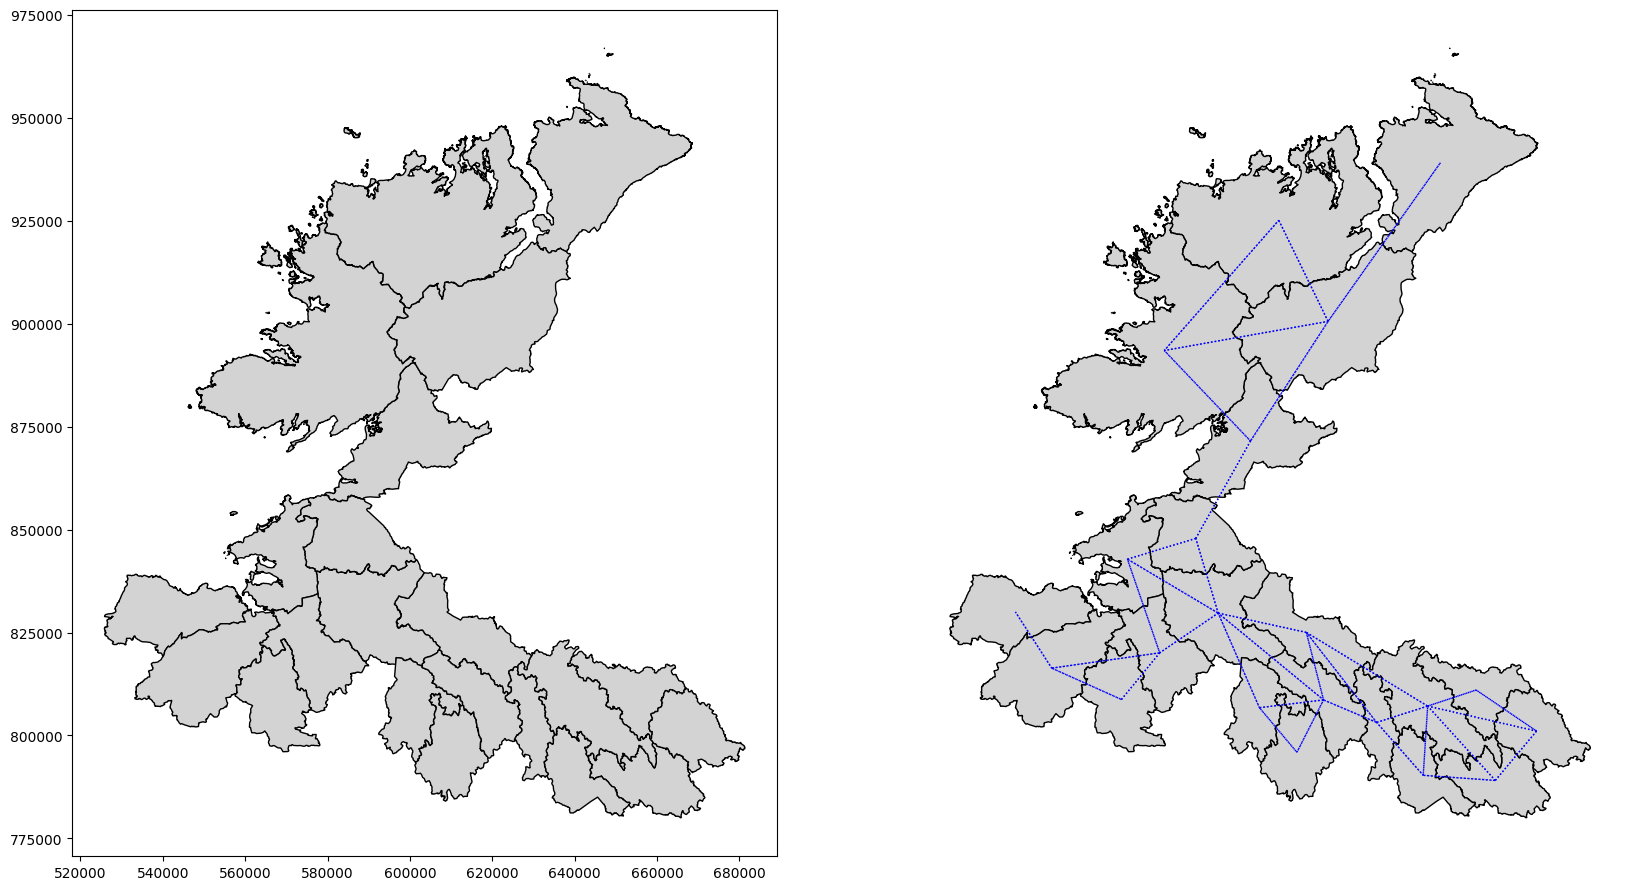

In [14]:
f, axs = plt.subplots(1, 2, figsize=(20, 20))
for i in range(2):
    ax = tuatha_nw_1600_mod.plot(
        edgecolor="k", facecolor="lightgray", ax=axs[i]
    )
airecht_w.plot(
    tuatha_nw_1600_mod,
    ax = axs[i],
    edge_kws=dict(color="b", linestyle=":", linewidth=1),       
    node_kws=dict(marker="")),

axs[i].set_axis_off()

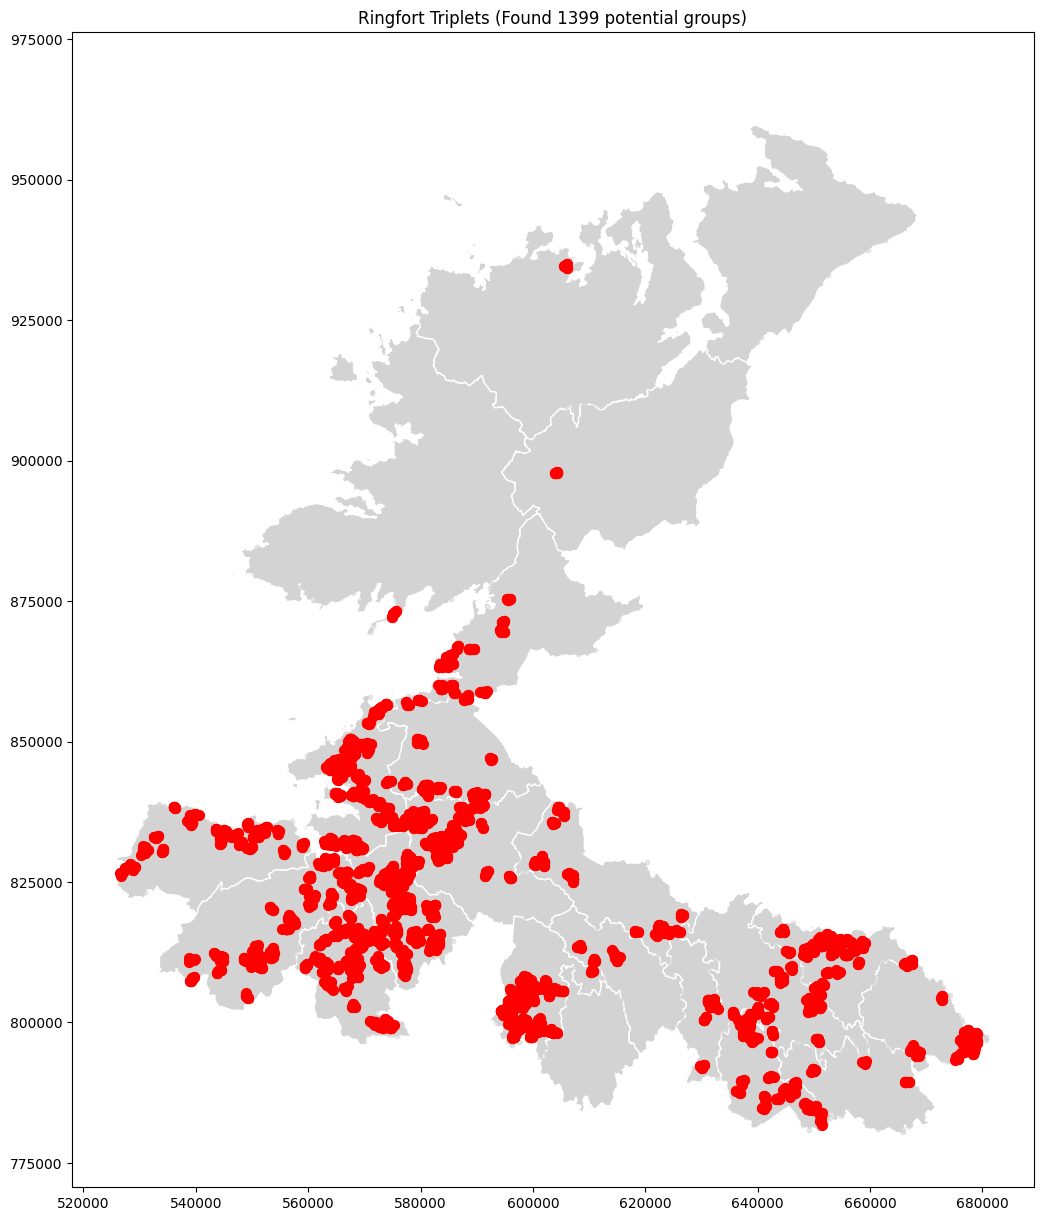

Total number of potential triplet groups: 1399
Average maximum internal distance: 547m


In [8]:
# Analysis of ringfort groupings
def analyze_triplet_patterns(ringforts, max_distance=800):  # distance in meters
    """
    Analyze patterns of ringfort triplets
    Parameters:
    - ringforts: GeoDataFrame of ringfort locations
    - max_distance: Maximum distance to consider for grouping (in meters)
    """
    # Create a spatial index for efficient neighbor finding
    from rtree import index
    
    # Initialize results storage
    triplets = []
    
    # For each ringfort
    for idx, center_fort in ringforts.iterrows():
        # Find all neighbors within max_distance
        nearby = ringforts[ringforts.geometry.distance(center_fort.geometry) <= max_distance]
        nearby = nearby[nearby.index != idx]  # exclude self
        
        # If we have at least 2 neighbors (to form a triplet)
        if len(nearby) >= 2:
            # Get distances to center fort
            distances = nearby.geometry.distance(center_fort.geometry)
            # Sort by distance
            nearby['dist_to_center'] = distances
            nearby = nearby.sort_values('dist_to_center')
            
            # Take the 2 nearest neighbors
            nearest_two = nearby.iloc[:2]
            
            # Calculate distances between all three forts
            max_internal_dist = max(
                nearest_two.iloc[0].geometry.distance(nearest_two.iloc[1].geometry),
                nearest_two.iloc[0].geometry.distance(center_fort.geometry),
                nearest_two.iloc[1].geometry.distance(center_fort.geometry)
            )
            
            # If maximum internal distance is within threshold
            if max_internal_dist <= max_distance:
                triplets.append({
                    'center': center_fort,
                    'neighbor1': nearest_two.iloc[0],
                    'neighbor2': nearest_two.iloc[1],
                    'max_dist': max_internal_dist
                })
    
    return triplets

# Run the analysis
triplet_groups = analyze_triplet_patterns(ringforts)

# Visualize triplets
fig, ax = plt.subplots(figsize=(15, 15))
tuatha_nw_1600_mod.plot(ax=ax, color='lightgrey', edgecolor='white')

# Plot all ringforts in light grey
ringforts.plot(ax=ax, color='lightgrey', alpha=0.5, markersize=10)

# Plot triplets with connections
for triplet in triplet_groups:
    # Get coordinates
    points = np.array([
        [triplet['center'].geometry.x, triplet['center'].geometry.y],
        [triplet['neighbor1'].geometry.x, triplet['neighbor1'].geometry.y],
        [triplet['neighbor2'].geometry.x, triplet['neighbor2'].geometry.y]
    ])
    
    # Plot points
    ax.scatter(points[:, 0], points[:, 1], c='red', s=50)
    
    # Plot connections
    for i in range(3):
        for j in range(i+1, 3):
            ax.plot([points[i,0], points[j,0]], 
                   [points[i,1], points[j,1]], 
                   'r-', alpha=0.5)

plt.title(f'Ringfort Triplets (Found {len(triplet_groups)} potential groups)')
plt.show()

# Print statistics
print(f"Total number of potential triplet groups: {len(triplet_groups)}")
print(f"Average maximum internal distance: {np.mean([t['max_dist'] for t in triplet_groups]):.0f}m")

In [23]:
tuatha_nw_1600_mod.columns
# ist unique values BY_ID
#tuatha_nw_1600_mod['BY_ID'].unique()
# list uniwue values in AIREACHT
#tuatha_nw_1600_mod['AIREACHT'].unique()
# list unique values in ENGLISH
tuatha_nw_1600_mod['ENGLISH'].unique()



array(['TIRHUGH', 'TULLYHAW', 'TULLYGARVEY', 'DRUMAHAIRE', 'CASTLERAHAN',
       'KILMACRENAN', 'CLANMAHON', 'LEITRIM', 'CLANKEE', 'TIRERAGH',
       'TULLYHUNCO', 'ROSCLOGHER', 'LEYNY', 'CARBURY', 'TIRERRILL',
       'MOHILL', 'CARRIGALLEN', 'INISHOWEN', 'RAPHOE', 'CORANN',
       'LOUGHTEE', 'BOYLAGH'], dtype=object)

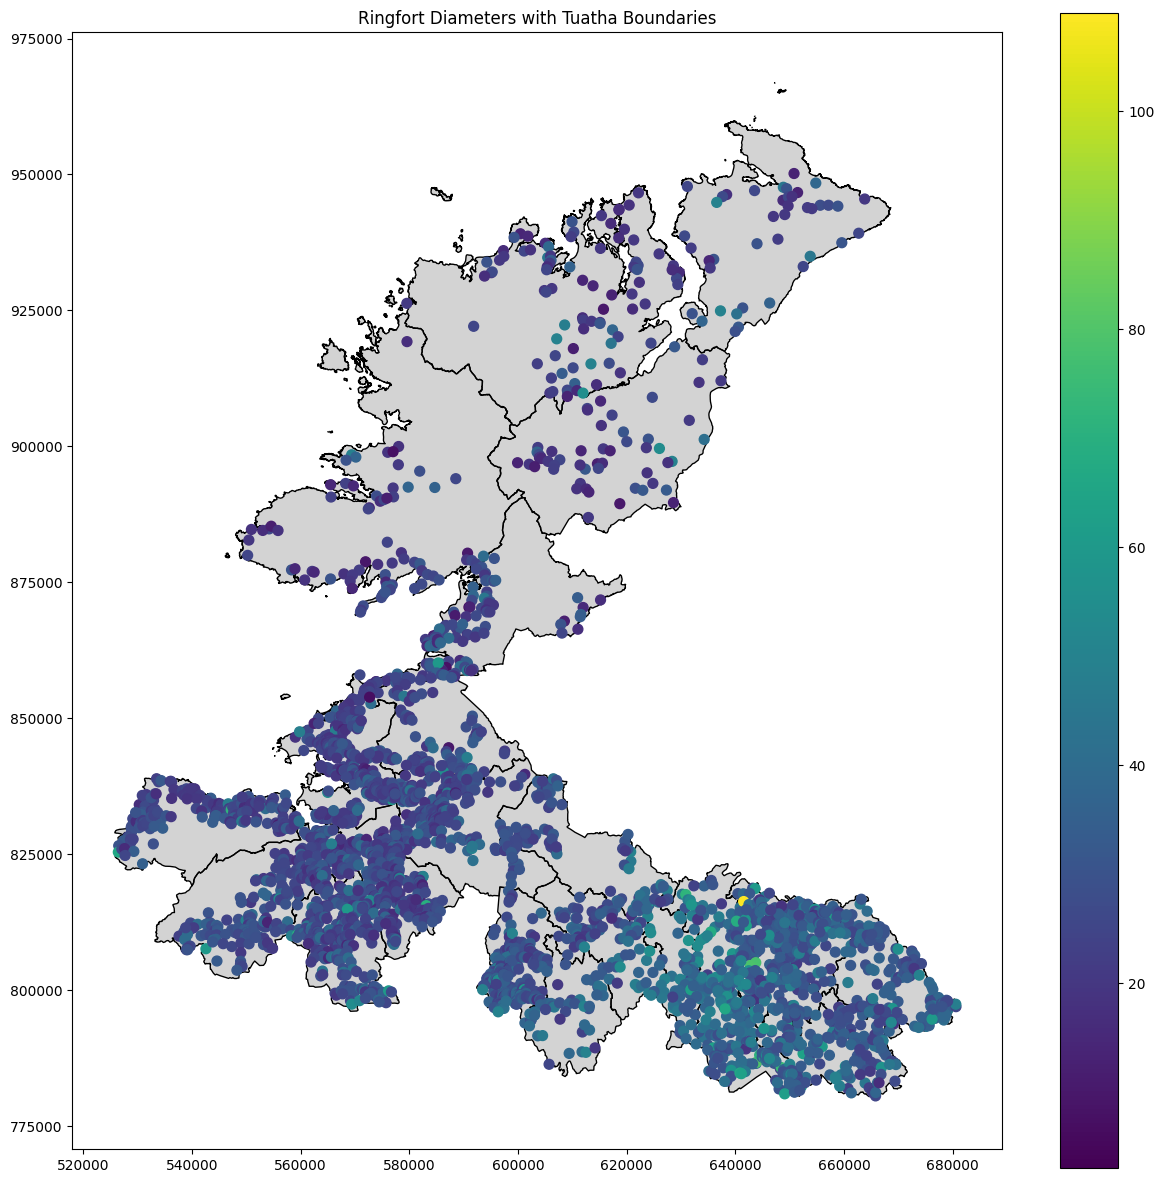

In [36]:
# Perform spatial join with tuatha boundaries
ringforts_with_tuatha = gpd.sjoin(ringforts, tuatha_nw_1600_mod, how='left', predicate='within')

# Calculate mean diameter by tuatha
tuatha_stats = ringforts_with_tuatha.groupby('ENGLISH')['diameter'].agg(['mean', 'count']).reset_index()

# Visualize
fig, ax = plt.subplots(figsize=(15, 15))
tuatha_nw_1600_mod.plot(ax=ax, color='lightgrey', edgecolor='white')
tuatha_nw_1600_mod.plot(ax=ax, color='none', edgecolor='black', linewidth=1)
ringforts.plot(ax=ax, column='diameter', cmap='viridis', 
               legend=True, markersize=50)
plt.title('Ringfort Diameters with Tuatha Boundaries')
plt.show()

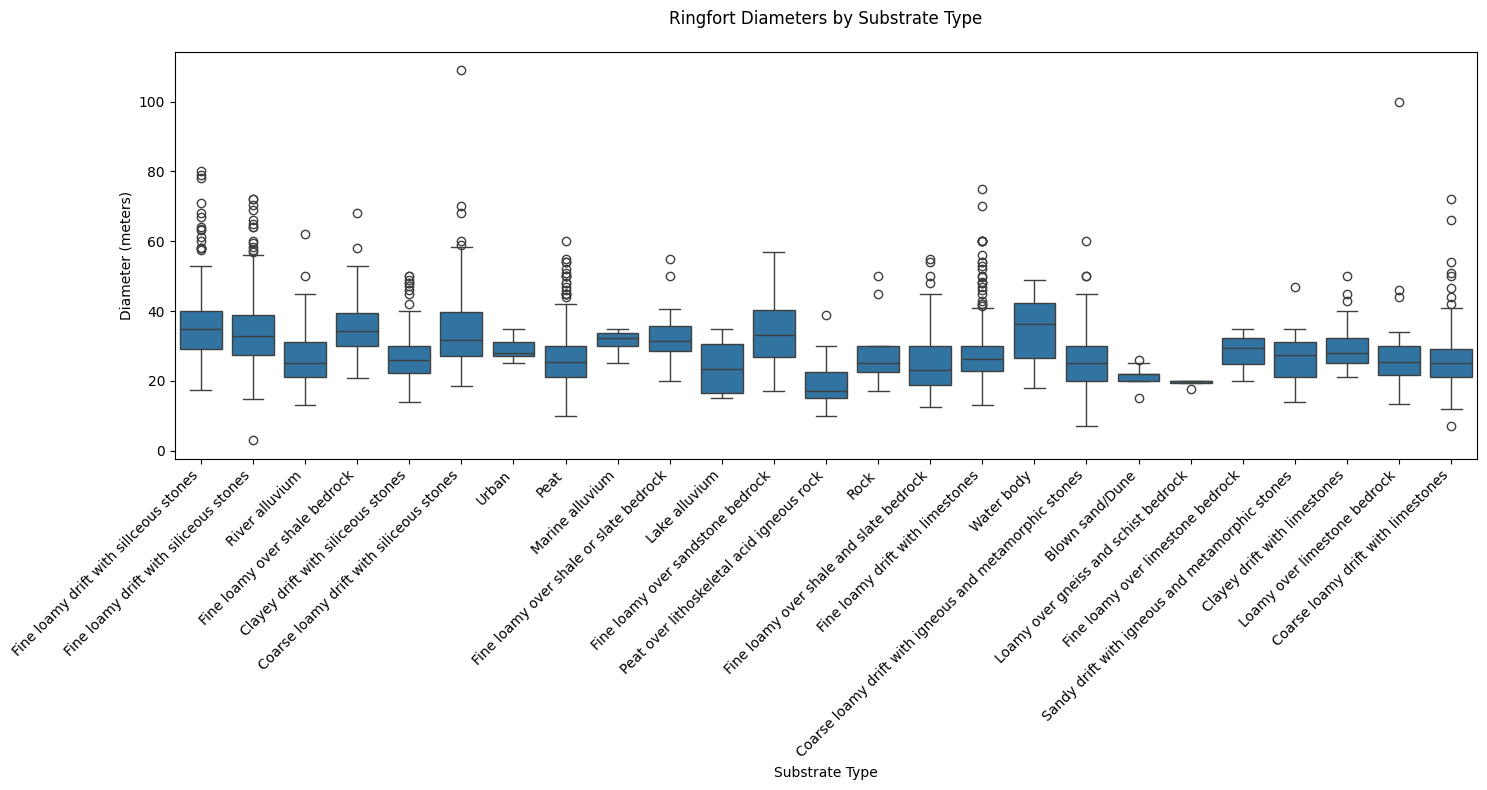


Summary Statistics by Substrate Type:
                                            substrate       mean        std  \
6                    Fine loamy drift with limestones  27.603983   7.271861   
8              Fine loamy drift with siliceous stones  33.983636   9.118579   
18                                               Peat  27.202326   8.343873   
4                  Coarse loamy drift with limestones  25.655500   7.167629   
7              Fine loamy drift with silIceous stones  36.034000  10.051821   
2                  Clayey drift with siliceous stones  27.055307   6.807342   
3   Coarse loamy drift with igneous and metamorphi...  25.107186   8.248157   
11            Fine loamy over shale and slate bedrock  25.210390   9.495547   
5            Coarse loamy drift with siliceous stones  36.287500  14.386241   
12                      Fine loamy over shale bedrock  35.686111   8.108096   
20                                     River alluvium  26.904545   8.914897   
10           

In [24]:
# Calculate statistics by substrate type
soil_stats = ringforts.groupby('substrate')['diameter'].agg([
    'mean', 'std', 'count'
]).reset_index()

# Visualize with better formatting
plt.figure(figsize=(15, 8))
ax = sns.boxplot(data=ringforts, x='substrate', y='diameter')

# Rotate x-axis labels for better readability
plt.xticks(rotation=45, ha='right')

# Add title and labels
plt.title('Ringfort Diameters by Substrate Type', pad=20)
plt.xlabel('Substrate Type')
plt.ylabel('Diameter (meters)')

# Adjust layout to prevent label cutoff
plt.tight_layout()
plt.show()

# Print summary statistics
print("\nSummary Statistics by Substrate Type:")
print(soil_stats.sort_values(by='count', ascending=False))

In [44]:
# Treat ringforts as spatial signals where:
# - Diameter = amplitude
# - Location = position
# - Substrate = propagation medium

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel

def spatial_signal_analysis(ringforts_ml):
    # Create the spatial signal model
    kernel = RBF([10.0, 10.0]) + WhiteKernel(noise_level=1)
    gpr = GaussianProcessRegressor(kernel=kernel)
    
    # Prepare spatial coordinates and diameters
    X = np.column_stack([ringforts_ml.geometry.x, ringforts_ml.geometry.y])
    y = ringforts_ml['diameter_normalized']
    
    # Fit the model
    gpr.fit(X, y)
    
    # Create a prediction grid
    x_range = np.linspace(X[:, 0].min(), X[:, 0].max(), 100)
    y_range = np.linspace(X[:, 1].min(), X[:, 1].max(), 100)
    xx, yy = np.meshgrid(x_range, y_range)
    
    # Predict intensity surface
    Z = gpr.predict(np.column_stack([xx.ravel(), yy.ravel()]))
    Z = Z.reshape(xx.shape)
    
    return xx, yy, Z

In [45]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

def predict_ringfort_locations():
    # Prepare features
    features = ['dist_to_boundary', 'diameter_local_mean', 'diameter_local_std'] + \
               [col for col in ringforts_ml.columns if col.startswith('soil_')] + \
               [col for col in ringforts_ml.columns if col.startswith('lisa_')]
    
    X = ringforts_ml[features]
    y = ringforts_ml['substrate']  # or another target variable
    
    # Split data
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)
    
    # Train model
    rf = RandomForestClassifier(n_estimators=100)
    rf.fit(X_train, y_train)
    
    # Get feature importance
    feature_importance = pd.DataFrame({
        'feature': features,
        'importance': rf.feature_importances_
    }).sort_values('importance', ascending=False)
    
    return rf, feature_importance

In [46]:
def analyze_spatial_patterns(ringforts_ml):
    # Create intensity surface using kernel density estimation
    from scipy.stats import gaussian_kde
    
    # Get point coordinates
    coords = np.vstack([ringforts_ml.geometry.x, ringforts_ml.geometry.y])
    
    # Calculate the kernel density
    kde = gaussian_kde(coords)
    
    # Create a grid of points
    xmin, xmax = coords[0].min(), coords[0].max()
    ymin, ymax = coords[1].min(), coords[1].max()
    
    x, y = np.mgrid[xmin:xmax:100j, ymin:ymax:100j]
    positions = np.vstack([x.ravel(), y.ravel()])
    
    # Calculate density
    z = kde(positions)
    
    return x, y, z.reshape(100, 100)